In [1]:
import json
import time
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader, Subset
from torchmetrics.detection import MeanAveragePrecision
from torchvision.models.detection import (
    FasterRCNN_MobileNet_V3_Large_320_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_320_fpn
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from torchvision.transforms import functional as F

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print("device:", device)


def set_seed(seed: int):
    # random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # torch.backends.cudnn.deterministic = True
    # torch.backends.cudnn.benchmark = False
    # torch.use_deterministic_algorithms(True, warn_only=False)

PyTorch version: 2.14.0+cu126
CUDA available: True
device: cuda


### Гиперпараметры

In [3]:
SEED = 42
set_seed(SEED)

TRAIN_IMAGES_PATH = Path("SVHN/train")
TRAIN_DIGIT_STRUCT_MAT = Path("SVHN/train_digitStruct.mat")
TRAIN_DIGIT_STRUCT_JSON = Path("SVHN/train_digit_struct.json")

TEST_IMAGES_PATH = Path("SVHN/test")
TEST_DIGIT_STRUCT_MAT = Path("SVHN/test_digitStruct.mat")
TEST_DIGIT_STRUCT_JSON = Path("SVHN/test_digit_struct.json")

# фон (0) + 10 цифр (1-10) = 11 классов
NUM_CLASSES = 11
TRAIN_DATASET_LENGTH = 1e10

VAL_FRACTION = 0.2
BATCH_SIZE = 8
EPOCHS = 10
LR = 4e-4

### Обработка датасета
Структура датасета:
- train/ - папка только с изображениями для обучения модели
- test/ - папка только с изображениями для итоговых метрик обученной модели
- train_digitStruct.mat - файл из матлаба с разметкой границ и их классов всех чисел на изображениях для обучения
- test_digitStruct.mat - аналогичен train_digitStruct.mat, но для изображений для теста



In [4]:
def test_mat_file():
    with h5py.File(TRAIN_DIGIT_STRUCT_MAT, "r") as f:
        print("Формат данных в train_digitStruct.mat:")
        digit_struct = f["digitStruct"]
        print(list(digit_struct.keys()))

        name_struct = f["digitStruct"]["name"][0][0]
        name_data = f[name_struct]
        name = "".join(chr(int(i[0])) for i in name_data)
        print(f"Название первого файла: {name}")

        # bbox - bounding box
        bbox_struct = f["digitStruct"]["bbox"][0][0]
        bbox_data = f[bbox_struct]
        bbox = list(i for i in bbox_data)
        print(f"Ключи параметров изображения: {bbox}")


def read_mat_digit_struct(mat_path: Path):
    marks = []
    with h5py.File(mat_path, "r") as f:
        names = f["digitStruct"]["name"]
        bboxes = f["digitStruct"]["bbox"]
        for name_ref, bbox_ref in zip(names, bboxes):
            # получаем имя файла с изображением
            name_data = f[name_ref[0]]
            image_name = "".join(chr(int(value[0])) for value in name_data)

            # получаем структуру с прямоугольниками
            bbox_group = f[bbox_ref[0]]

            # считываем параметры прямоугольников
            fields = {}
            for field in ["left", "top", "width", "height", "label"]:
                data = bbox_group[field]

                if data.shape[0] == 1:
                    # если на изображении только 1 цифра
                    fields[field] = [float(data[0][0])]
                else:
                    # если цифр несколько
                    fields[field] = [float(f[ref][0][0]) for ref in data[:, 0]]

            # формируем словарь с параметрами прямоугольника
            image_boxes = []
            for i in range(len(fields["label"])):
                image_boxes.append({
                    "left": fields["left"][i],
                    "top": fields["top"][i],
                    "width": fields["width"][i],
                    "height": fields["height"][i],
                    "label": int(fields["label"][i])
                })

            # собираем итоговый массив словарей (json)
            marks.append({
                "filename": image_name,
                "boxes": image_boxes
            })

    return marks


def get_digit_struct(json_path: Path, mat_path: Path):
    if json_path.exists():
        with open(json_path, "r", encoding="utf-8") as f:
            train_digit_struct = json.load(f)
    else:
        with open(json_path, "w", encoding="utf-8") as f:
            train_digit_struct = read_mat_digit_struct(mat_path)
            json.dump(train_digit_struct, f)

    return train_digit_struct


test_mat_file()
train_digit_struct = get_digit_struct(TRAIN_DIGIT_STRUCT_JSON, TRAIN_DIGIT_STRUCT_MAT)
print(f"\nДанные для первого изображения:\n{train_digit_struct[0]}")

Формат данных в train_digitStruct.mat:
['bbox', 'name']
Название первого файла: 1.png
Ключи параметров изображения: ['height', 'label', 'left', 'top', 'width']

Данные для первого изображения:
{'filename': '1.png', 'boxes': [{'left': 246.0, 'top': 77.0, 'width': 81.0, 'height': 219.0, 'label': 1}, {'left': 323.0, 'top': 81.0, 'width': 96.0, 'height': 219.0, 'label': 9}]}


Главная проблема в файлах из Matlab - для их обработки будем использовать библиотеку h5py. В файлах *_digitStruct.mat данные представлены в своём виде (что-то наподобие ссылок), что затрудняет работу с ними, поэтому с помощью функции read_mat_digit_struct преобразуем эти данные в json-формат. В итоге получаем уже понятный формат для определения положения и классов рамок объектов:

    'filename': '1.png',
    'boxes': [
    {
        'left': 246.0,
        'top': 77.0,
        'width': 81.0,
        'height': 219.0,
        'label': 1
    },
    {
        'left': 323.0,
        'top': 81.0,
        'width': 96.0,
        'height': 219.0,
        'label': 9
    }

In [5]:
class SVHNDataset(Dataset):
    def __init__(self, image_dir, struct_json_path, struct_mat_path):
        self.image_dir = Path(image_dir)
        self.marks = get_digit_struct(struct_json_path, struct_mat_path)

    def __len__(self):
        return len(self.marks)

    def __getitem__(self, idx):
        mark = self.marks[idx]

        image_path = self.image_dir / mark["filename"]
        with Image.open(image_path) as img:
            image = img.convert("RGB")
            image_width, image_height = image.size

        boxes = []
        labels = []
        for box in mark["boxes"]:
            x1 = box["left"]
            y1 = box["top"]
            x2 = x1 + box["width"]
            y2 = y1 + box["height"]

            # на всякий случай ограничивает bbox, чтобы он не выходил за изображения
            x1 = max(0, min(x1, image_width))
            y1 = max(0, min(y1, image_height))
            x2 = max(0, min(x2, image_width))
            y2 = max(0, min(y2, image_height))

            if x2 <= x1 or y2 <= y1:
                continue

            boxes.append([x1, y1, x2, y2])
            labels.append(box["label"])

        image = F.to_tensor(image)
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(labels, dtype=torch.int64)
        target = {
            "boxes": boxes,
            "labels": labels
        }

        return image, target

In [6]:
full_train_dataset = SVHNDataset(TRAIN_IMAGES_PATH, TRAIN_DIGIT_STRUCT_JSON, TRAIN_DIGIT_STRUCT_MAT)

indices = np.arange(min(len(full_train_dataset), TRAIN_DATASET_LENGTH))
train_indices, val_indices = train_test_split(
    indices,
    test_size=VAL_FRACTION,
    random_state=SEED,
    shuffle=True
)

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_train_dataset, val_indices)
test_dataset = SVHNDataset(TEST_IMAGES_PATH, TEST_DIGIT_STRUCT_JSON, TEST_DIGIT_STRUCT_MAT)


def collate_fn(batch):
    return tuple(zip(*batch))


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    pin_memory=(device.type == "cuda")
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    pin_memory=(device.type == "cuda")
)

### Отображение изображений с разметками (bboxes)

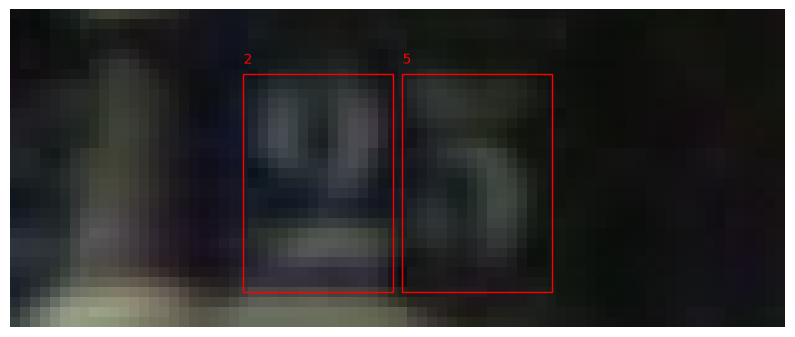

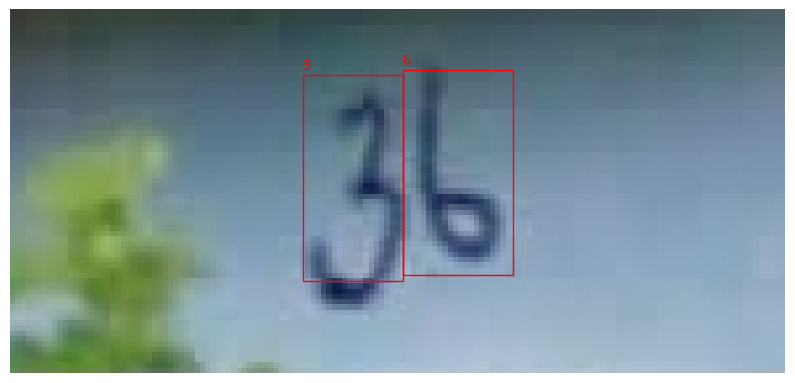

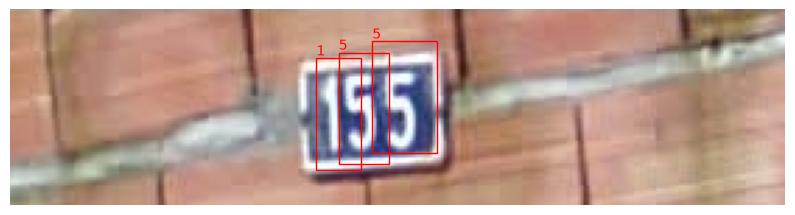

In [7]:
def show_image_with_bboxes(
        dataset: Dataset,
        indices: list[int] | range | int
):
    if isinstance(indices, int):
        indices = [indices]
    for idx in indices:
        image, target = dataset[idx]
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(image.permute(1, 2, 0))

        for box, label in zip(target["boxes"], target["labels"]):
            x1, y1, x2, y2 = box.tolist()
            rect = plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=1,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)
            ax.text(x1, y1 - 1, str(label.item()), color="red")

        plt.axis("off")


show_image_with_bboxes(train_dataset, range(3, 6))

### Создание модели
В качестве модели используется готовая модель fasterrcnn_resnet50_fpn из pytorch. В этой модели ResNet отвечает за извлечение признаков с изображений, FPN (Feature Pyramid Network) формирует карты признаков разных масштабов и уже сам FasterRCNN по полученным картам из FPN предсказывает их классы и смещения.
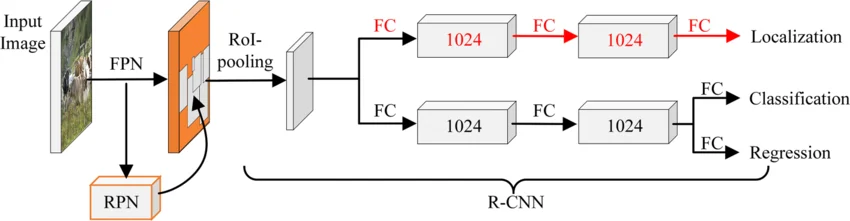
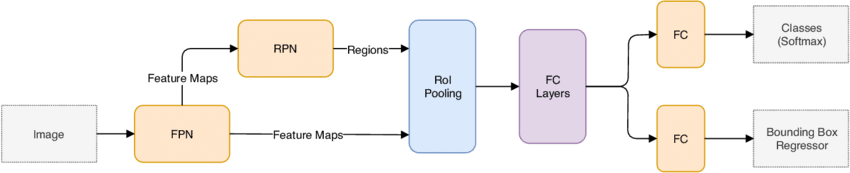

In [8]:
class MyFasterRCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        weights = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT
        self.model = fasterrcnn_mobilenet_v3_large_320_fpn(
            weights=weights,
            trainable_backbone_layers=2
        )

        # заменяем классификационную голову
        in_features = self.model.roi_heads.box_predictor.cls_score.in_features
        self.model.roi_heads.box_predictor = FastRCNNPredictor(
            in_features,
            num_classes
        )

    def forward(self, images, targets=None):
        return self.model(images, targets)

### Обучение модели

In [9]:
def calculate_metrics(
        all_predictions,
        all_targets,
        iou_threshold=0.5,  # рамка считается правильной, если расчитанный IoU > iou_threshold
        score_threshold=0.5 # при подсчёте Precision/Recall учитываются предсказания с вероятностями не менее score_threshold
):
    # приводим данные к нужным типам
    predictions = []
    targets = []
    for pred, target in zip(all_predictions, all_targets):
        pred_boxes = pred["boxes"].to(dtype=torch.float32).reshape(-1, 4)
        pred_labels = pred["labels"].to(dtype=torch.int64).reshape(-1)
        pred_scores = pred["scores"].to(dtype=torch.float32).reshape(-1)
        target_boxes = target["boxes"].to(dtype=torch.float32).reshape(-1, 4)
        target_labels = target["labels"].to(dtype=torch.int64).reshape(-1)

        predictions.append({
            "boxes": pred_boxes,
            "labels": pred_labels,
            "scores": pred_scores
        })
        targets.append({
            "boxes": target_boxes,
            "labels": target_labels
        })

    # счётчики для метрик
    TP = 0
    FP = 0
    FN = 0
    matched_ious = []

    for pred, target in zip(predictions, targets):
        pred_boxes = pred["boxes"]
        pred_labels = pred["labels"]
        pred_scores = pred["scores"]

        target_boxes = target["boxes"]
        target_labels = target["labels"]

        # рассматриваем каждый класс по отдельности
        classes = torch.unique(torch.cat((pred_labels, target_labels)))

        for class_id in classes.tolist():
            # из предсказаний отбираем те, которые имеют вероятность больше score_threshold
            pred_indices = torch.where(
                (pred_labels == class_id) &
                (pred_scores >= score_threshold)
            )[0]

            # из отобранных предсказаний отбираем те, которые совпадают с рассматриваемым классом
            target_indices = torch.where(target_labels == class_id)[0]

            # если предсказаний вообще нет, то все объекты предсказаны неверно
            if len(target_indices) == 0:
                FP += len(pred_indices)
                continue

            # Нет предсказаний: все настоящие объекты пропущены.
            if len(pred_indices) == 0:
                FN += len(target_indices)
                continue

            # вычисляем IoU
            ious = box_iou(pred_boxes[pred_indices], target_boxes[target_indices])
            # для правильного подсчёта IoU надо отсортировать предсказания по убыванию их вероятности
            order = torch.argsort(pred_scores[pred_indices], descending=True)
            ious = ious[order]

            # отмечаем, какие настоящие объекты уже сопоставлены
            available_targets = torch.ones(len(target_indices), dtype=torch.bool)

            for i in range(len(pred_indices)):
                # уже сопоставленные объекты нельзя использовать повторно
                current_ious = ious[i].clone()
                current_ious[~available_targets] = -1.0

                best_iou, best_target = current_ious.max(dim=0)
                if best_iou.item() >= iou_threshold:
                    TP += 1
                    available_targets[best_target] = False
                    matched_ious.append(best_iou.item())
                else:
                    FP += 1
            FN += int(available_targets.sum().item())

    # вычисляем итоговые значения
    eps = 1e-7
    precision = TP / (TP + FP + eps)
    recall = TP / (TP + FN + eps)
    if matched_ious:
        mean_iou = sum(matched_ious) / len(matched_ious)
    else:
        mean_iou = 0.0

    # для вычисления mAP просто воспользуемся готовой библиотекой
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    metric.update(predictions, targets)
    map_results = metric.compute()

    return {
        "iou": mean_iou,
        "precision": precision,
        "recall": recall,
        "map": map_results["map"].item(),
        "map_50": map_results["map_50"].item(),
        "map_75": map_results["map_75"].item()
    }

In [10]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    all_predictions = []
    all_targets = []
    for images, targets in loader:
        # переносим на device (cuda)
        images = [image.to(device, non_blocking=True) for image in images]

        # получаем предсказания модели на device (cuda)
        predictions = model(images)

        # сохраняем результаты на CPU
        all_predictions.extend([
            {key: value.detach().cpu() for key, value in prediction.items()}
            for prediction in predictions
        ])
        all_targets.extend([
            {key: value.detach().cpu() for key, value in target.items()}
            for target in targets
        ])

    return calculate_metrics(all_predictions, all_targets)

In [11]:
def train(
        model, optimizer,
        train_loader, val_loader, epochs,
        n_early_stopping: int = 5,
        verbose: bool = True,
        save_path: str | None = "best_model.pth"
):
    history = {
        "train_loss": [],
        "val_precision": [],
        "val_recall": [],
        "val_iou": [],
        "val_map": [],
        "val_map_50": [],
        "val_map_75": []
    }

    best_val_map = -1.0
    epochs_no_improve = 0

    for epoch in range(epochs):
        model.train()
        time_epoch_start = time.time()

        train_loss_sum = 0.0
        train_seen = 0

        for images, targets in train_loader:
            images = [
                image.to(device, non_blocking=True)
                for image in images
            ]

            targets = [
                {
                    key: value.to(device, non_blocking=True)
                    for key, value in target.items()
                }
                for target in targets
            ]

            optimizer.zero_grad(set_to_none=True)
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())
            loss.backward()
            optimizer.step()

            batch_size = len(images)
            train_loss_sum += loss.item() * batch_size
            train_seen += batch_size

        train_loss = train_loss_sum / train_seen
        val_metrics = evaluate(model, val_loader)
        val_iou = val_metrics["iou"]
        val_precision = val_metrics["precision"]
        val_recall = val_metrics["recall"]
        val_map = val_metrics["map"]
        val_map_50 = val_metrics["map_50"]
        val_map_75 = val_metrics["map_75"]

        history["train_loss"].append(float(train_loss))
        history["val_iou"].append(val_iou)
        history["val_precision"].append(val_precision)
        history["val_recall"].append(val_recall)
        history["val_map"].append(val_map)
        history["val_map_50"].append(val_map_50)
        history["val_map_75"].append(val_map_75)

        if verbose:
            print(
                f"[{epoch + 1:02d}/{epochs}] "
                f"loss={train_loss:.4f}  "
                f"precision={val_precision:.4f}  "
                f"recall={val_recall:.4f}  "
                f"IoU={val_iou:.4f}  "
                f"mAP={val_map:.4f}  "
                f"mAP@0.5={val_map_50:.4f}  "
                f"mAP@0.75={val_map_75:.4f}  "
                f"time={time.time() - time_epoch_start:.0f}s"
            )

        # early stopping
        if val_map > best_val_map:
            best_val_map = val_map
            epochs_no_improve = 0
            # сохраняем веса на диск
            if save_path is not None:
                torch.save(model.state_dict(), save_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= n_early_stopping:
                if verbose:
                    print(
                        f"early stop on epoch {epoch + 1}, "
                        f"best best_val_map={best_val_map:.4f}"
                    )
                break

    # возвращаем модели её лучшие веса
    if save_path is not None and Path(save_path).exists():
        model.load_state_dict(torch.load(save_path, map_location=device, weights_only=True))
        if verbose:
            print(f"loaded best state (best_val_map={best_val_map:.4f})")

    return history

In [12]:
model = MyFasterRCNN(num_classes=NUM_CLASSES).to(device)
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR, weight_decay=5e-4
)

history = train(
    model, optimizer,
    train_loader, val_loader,
    epochs=EPOCHS,
    n_early_stopping=5,
    save_path=None
)

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to C:\Users\116wi/.cache\torch\hub\checkpoints\fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:02<00:00, 35.0MB/s]


started validation after 282.69819259643555 s
[01/10] loss=1.6174  precision=0.8441  recall=0.7082  IoU=0.7528  mAP=0.3802  mAP@0.5=0.8136  mAP@0.75=0.2873  time=336s
started validation after 278.98718094825745 s
[02/10] loss=1.4461  precision=0.8644  recall=0.7789  IoU=0.7541  mAP=0.4028  mAP@0.5=0.8546  mAP@0.75=0.3099  time=331s
started validation after 278.0678470134735 s
[03/10] loss=1.4321  precision=0.8585  recall=0.8147  IoU=0.7548  mAP=0.4174  mAP@0.5=0.8686  mAP@0.75=0.3291  time=330s
started validation after 280.74547958374023 s
[04/10] loss=1.4214  precision=0.8751  recall=0.8256  IoU=0.7548  mAP=0.4226  mAP@0.5=0.8813  mAP@0.75=0.3300  time=335s
started validation after 293.05231857299805 s
[05/10] loss=1.4030  precision=0.8630  recall=0.8415  IoU=0.7576  mAP=0.4278  mAP@0.5=0.8812  mAP@0.75=0.3458  time=346s
started validation after 278.2827570438385 s
[06/10] loss=1.3883  precision=0.8800  recall=0.8387  IoU=0.7589  mAP=0.4345  mAP@0.5=0.8900  mAP@0.75=0.3535  time=329s


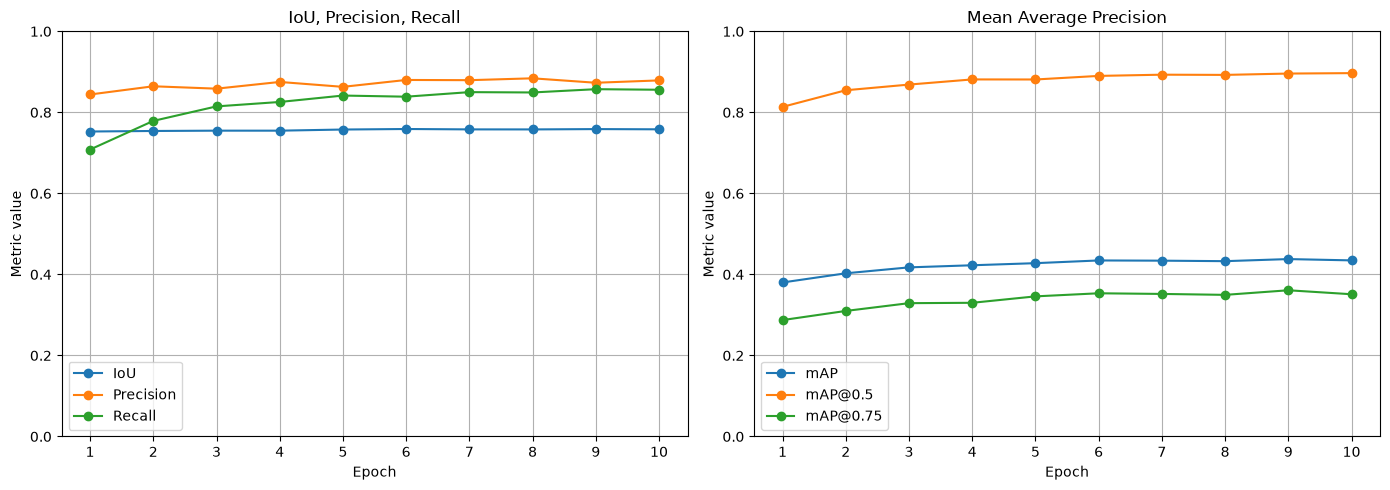

In [13]:
def show_plot_metrics(history):
    epochs = range(1, len(history["val_map"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, history["val_iou"], marker="o", label="IoU")
    axes[0].plot(epochs, history["val_precision"], marker="o", label="Precision")
    axes[0].plot(epochs, history["val_recall"], marker="o", label="Recall")
    axes[0].set_title("IoU, Precision, Recall")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Metric value")
    axes[0].set_ylim(0, 1)
    axes[0].set_xticks(list(epochs))
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(epochs, history["val_map"], marker="o", label="mAP")
    axes[1].plot(epochs, history["val_map_50"], marker="o", label="mAP@0.5")
    axes[1].plot(epochs, history["val_map_75"], marker="o", label="mAP@0.75")
    axes[1].set_title("Mean Average Precision")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Metric value")
    axes[1].set_ylim(0, 1)
    axes[1].set_xticks(list(epochs))
    axes[1].grid(True)
    axes[1].legend()

    plt.tight_layout()
    plt.show()


show_plot_metrics(history)

### Проверка на тесте

In [14]:
test_metrics = evaluate(model, test_loader)

print("\nМетрики на test:")
print(f"IoU      : {test_metrics['iou']:.4f}")
print(f"Precision: {test_metrics['precision']:.4f}")
print(f"Recall   : {test_metrics['recall']:.4f}")
print(f"mAP      : {test_metrics['map']:.4f}")
print(f"mAP@0.5  : {test_metrics['map_50']:.4f}")
print(f"mAP@0.75 : {test_metrics['map_75']:.4f}")


Метрики на test:
IoU      : 0.7366
Precision: 0.8068
Recall   : 0.6918
mAP      : 0.3245
mAP@0.5  : 0.7474
mAP@0.75 : 0.2168


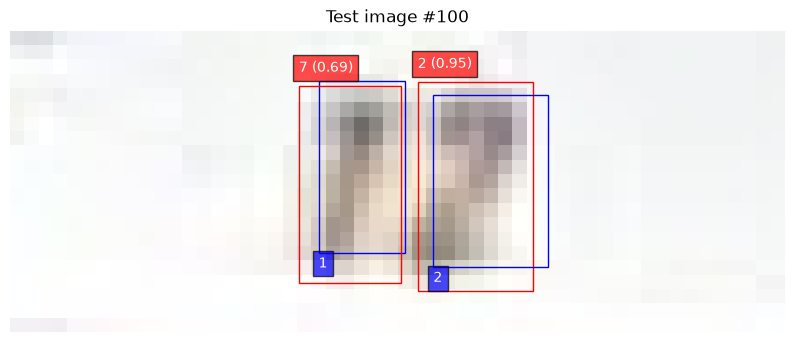

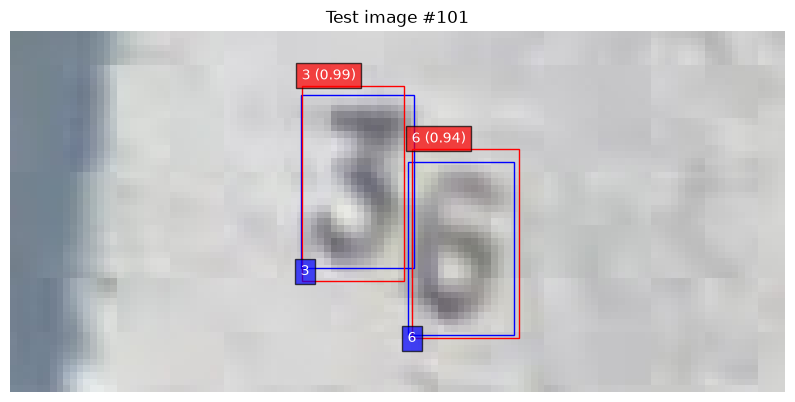

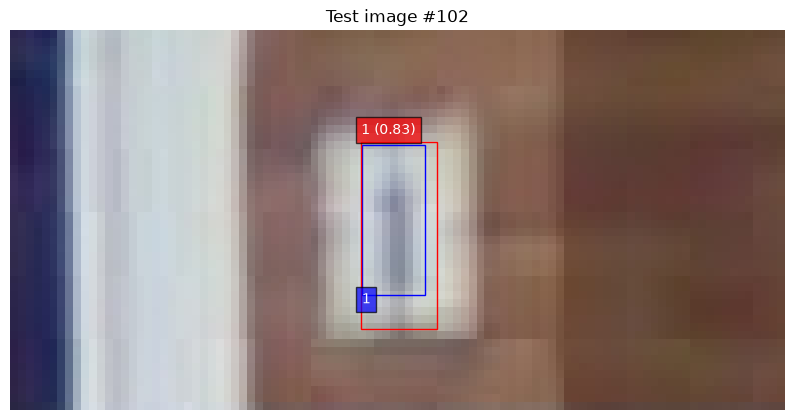

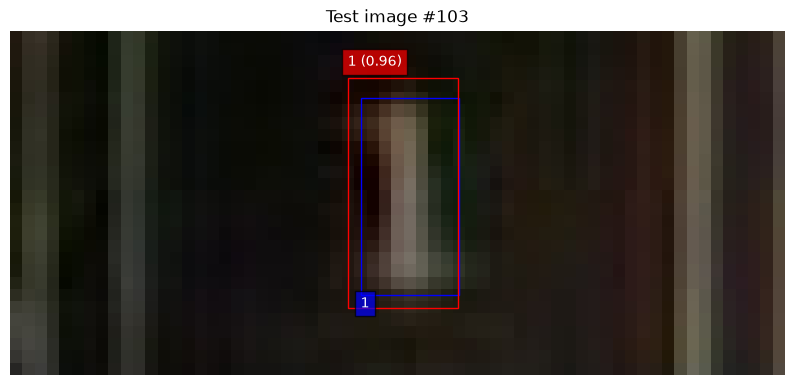

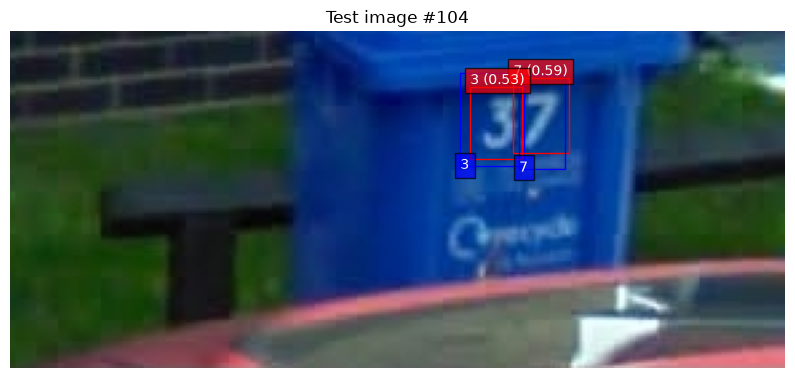

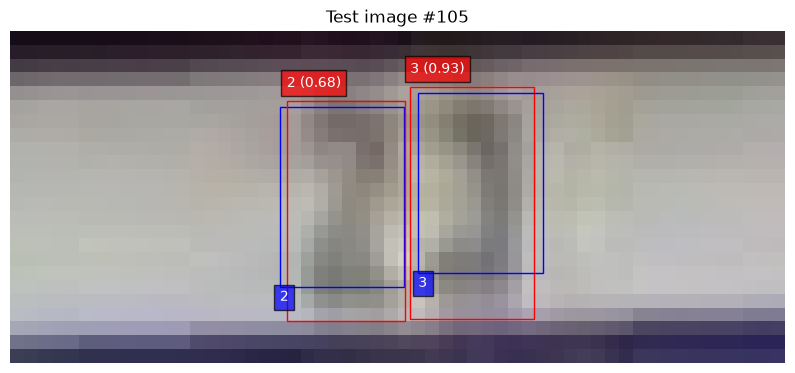

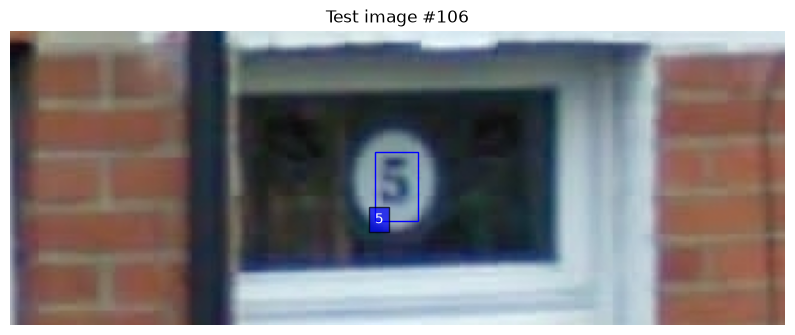

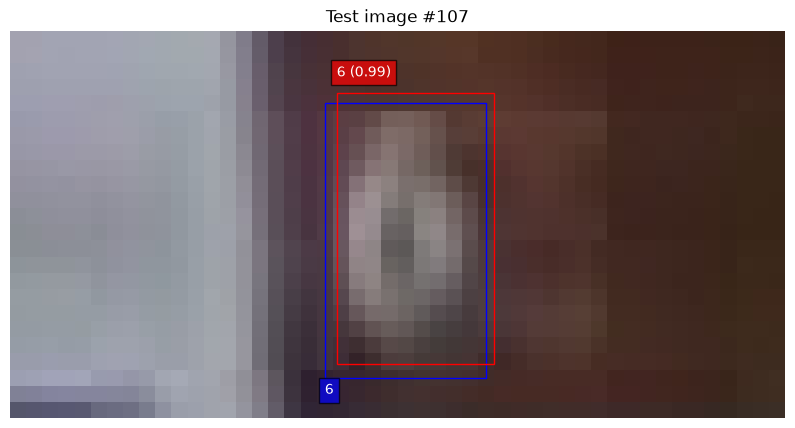

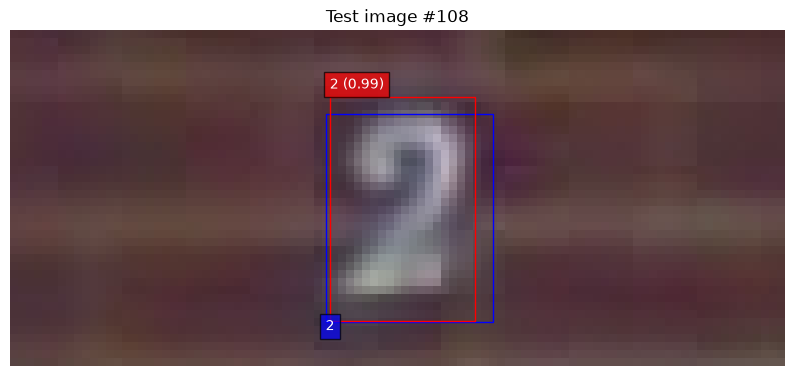

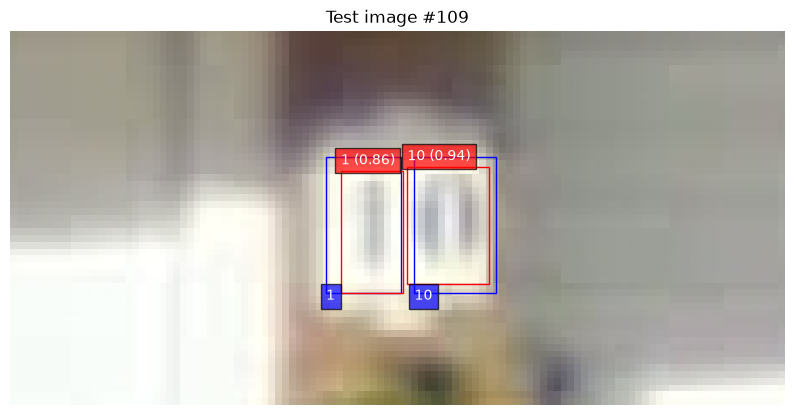

In [22]:
def show_test_image_with_bboxes(
        model,
        indices: list[int] | range | int,
        score_threshold: float = 0.5
):
    if isinstance(indices, int):
        indices = [indices]

    model.eval()

    with torch.no_grad():
        for idx in indices:
            image, target = test_dataset[idx]
            prediction = model([image.to(device)])[0]

            fig, ax = plt.subplots(figsize=(10, 6))
            ax.imshow(image.permute(1, 2, 0))

            for box, label, score, real_box, real_label in zip(
                prediction["boxes"],
                prediction["labels"],
                prediction["scores"],
                target["boxes"],
                target["labels"]
            ):
                # отрисовка реального бокса
                x1, y1, x2, y2 = real_box.cpu().tolist()
                rect = plt.Rectangle(
                    (x1, y1),
                    x2 - x1,
                    y2 - y1,
                    linewidth=1,
                    edgecolor="blue",
                    facecolor="none"
                )
                ax.add_patch(rect)
                ax.text(
                    x1, y2 + 1,
                    f"{real_label.item()}",
                    color="white",
                    fontsize=10,
                    bbox=dict(facecolor="blue", alpha=0.7)
                )

                if score < score_threshold:
                    continue

                # отрисовка предсказанного бокса
                x1, y1, x2, y2 = box.cpu().tolist()
                rect = plt.Rectangle(
                    (x1, y1),
                    x2 - x1,
                    y2 - y1,
                    linewidth=1,
                    edgecolor="red",
                    facecolor="none"
                )
                ax.add_patch(rect)
                ax.text(
                    x1, y1 - 1,
                    f"{label.item()} ({score.item():.2f})",
                    color="white",
                    fontsize=10,
                    bbox=dict(facecolor="red", alpha=0.7)
                )

            ax.set_title(f"Test image #{idx}")
            ax.axis("off")
            plt.show()


show_test_image_with_bboxes(model, range(100, 110))